## Libraries

In [2]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Import Dataset

In [7]:
X, _ = make_blobs(
    n_samples=5000,
    n_features=2,
    centers=4,
    random_state=42
)

data = pd.DataFrame(X)
print(data.head())

          0         1
0  3.654075  1.689015
1 -8.121874 -8.005697
2  3.792245  1.321081
3 -7.982812 -6.059556
4 -9.300861  7.711203


## Train the Model

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = DBSCAN (
    eps=0.06,
    min_samples=5
)

labels = model.fit_predict(X_scaled)

X_original = pd.DataFrame(X)
X_original["Cluster"] = labels


## Visualization

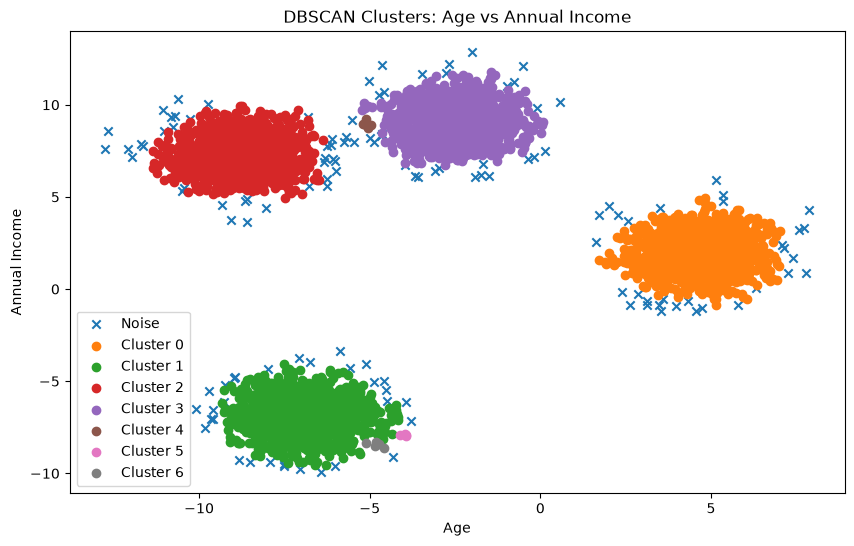

In [9]:
plt.figure(figsize=(10, 6))

for cluster in sorted(X_original["Cluster"].unique()):
    cluster_data = X_original[
        X_original["Cluster"] == cluster
    ]

    if cluster == -1:
        plt.scatter(
            cluster_data[0],
            cluster_data[1],
            label = "Noise",
            marker="x"
        )
    else:
        plt.scatter(
            cluster_data[0],
            cluster_data[1],
            label=f"Cluster {cluster}"
        )

plt.xlabel("Age")
plt.ylabel("Annual Income")
plt.title("DBSCAN Clusters: Age vs Annual Income")
plt.legend()
plt.show()